# Part 10: Summary Chart

### Ramith Vaid | NTU Singapore

This notebook draws the consolidated chart for the portfolio project from the CSV files each part saved, and prints a line of key numbers per part. It runs no optimizations. The written summary is in `SUMMARY.md`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print('Libraries loaded.')

Libraries loaded.


## 1. Load the saved tables

In [2]:
p2 = pd.read_csv('part2_rolling_dcc_comparison.csv')
p3 = pd.read_csv('part3_cost_sensitivity.csv')
p4a = pd.read_csv('part4_asset_vol_errors.csv')
p4p = pd.read_csv('part4_portfolio_vol_errors.csv')
p5 = pd.read_csv('part5_risk_free_comparison.csv')
p6 = pd.read_csv('part6_bootstrap_sharpe.csv', index_col=0)
p7 = pd.read_csv('part7_cvar_results.csv')
p8v = pd.read_csv('part8_vol_error_by_window_length.csv')
p8p = pd.read_csv('part8_performance_by_window_length.csv')
print('Loaded.')

Loaded.


## 2. Key numbers

In [3]:
ex = p2[p2['window'] != 3]
print('Part 2   mean vol error excl. COVID (sample / static / DCC): '
      f"{ex['sample_error'].mean()*100:.2f}% / {ex['garch_static_error'].mean()*100:.2f}% / {ex['garch_dcc_error'].mean()*100:.2f}%")
c = p3[(p3.optimizer == 'cost-blind') & (p3.cost_bps == 10)].set_index('covariance')['net_sharpe']
print('Part 3   net Sharpe at 10 bps, cost-blind:', c.round(3).to_dict())
a = p4a[~p4a['covid']]
print(f"Part 4   asset-level error excl. COVID: sample {a['sample_err'].mean()*100:.2f}%, GARCH {a['garch_err'].mean()*100:.2f}%")
t = p5[p5.universe == '8 US stocks'].pivot(index='strategy', columns='optimizer_rf', values='sharpe_vs_tbill')
print('Part 5   Sharpe vs T-bill, 8 stocks (fixed 2% / window T-bill in optimizer):', {k: (round(v['fixed 2%'], 3), round(v['window T-bill'], 3)) for k, v in t.iterrows()})
print('Part 6   Sharpe points:', p6['sharpe_point'].round(3).to_dict())
q = p7[p7.universe == '8 assets'].set_index('strategy')
print('Part 7   8 stocks Sharpe / max drawdown:', {k: (round(r['sharpe'], 3), round(r['max_dd_%'], 1)) for k, r in q.iterrows()})
v8 = p8v[p8v.windows == 'excluding COVID window'].set_index('config')
print('Part 8   vol error excl. COVID by config (sample / static / DCC):', {k: tuple(np.round(r[['Sample error %', 'GARCH static error %', 'GARCH DCC error %']].values.astype(float), 2)) for k, r in v8.iterrows()})

Part 2   mean vol error excl. COVID (sample / static / DCC): 5.78% / 4.32% / 3.92%
Part 3   net Sharpe at 10 bps, cost-blind: {'Sample covariance': 0.791, 'GARCH + static corr': 0.852, 'GARCH + DCC corr': 0.854}
Part 4   asset-level error excl. COVID: sample 4.94%, GARCH 4.93%
Part 5   Sharpe vs T-bill, 8 stocks (fixed 2% / window T-bill in optimizer): {'Equal weight (1/N)': (np.float64(1.061), np.float64(1.061)), 'GARCH + DCC corr': (np.float64(0.816), np.float64(0.857)), 'GARCH + static corr': (np.float64(0.816), np.float64(0.862)), 'Sample': (np.float64(0.756), np.float64(0.782))}
Part 6   Sharpe points: {'Sample (8)': 0.782, 'GARCH static (8)': 0.862, 'GARCH DCC (8)': 0.857, 'Equal weight (8)': 1.061, 'Sample (13)': 0.87, 'GARCH static (13)': 0.817, 'GARCH DCC (13)': 0.865, 'Equal weight (13)': 0.962, 'S&P 500 (SPY)': 0.76}
Part 7   8 stocks Sharpe / max drawdown: {'Max Sharpe (sample)': (0.782, -28.1), 'Min variance (sample)': (0.67, -31.9), 'Min variance (GARCH)': (0.741, -32.6),

## 3. Chart

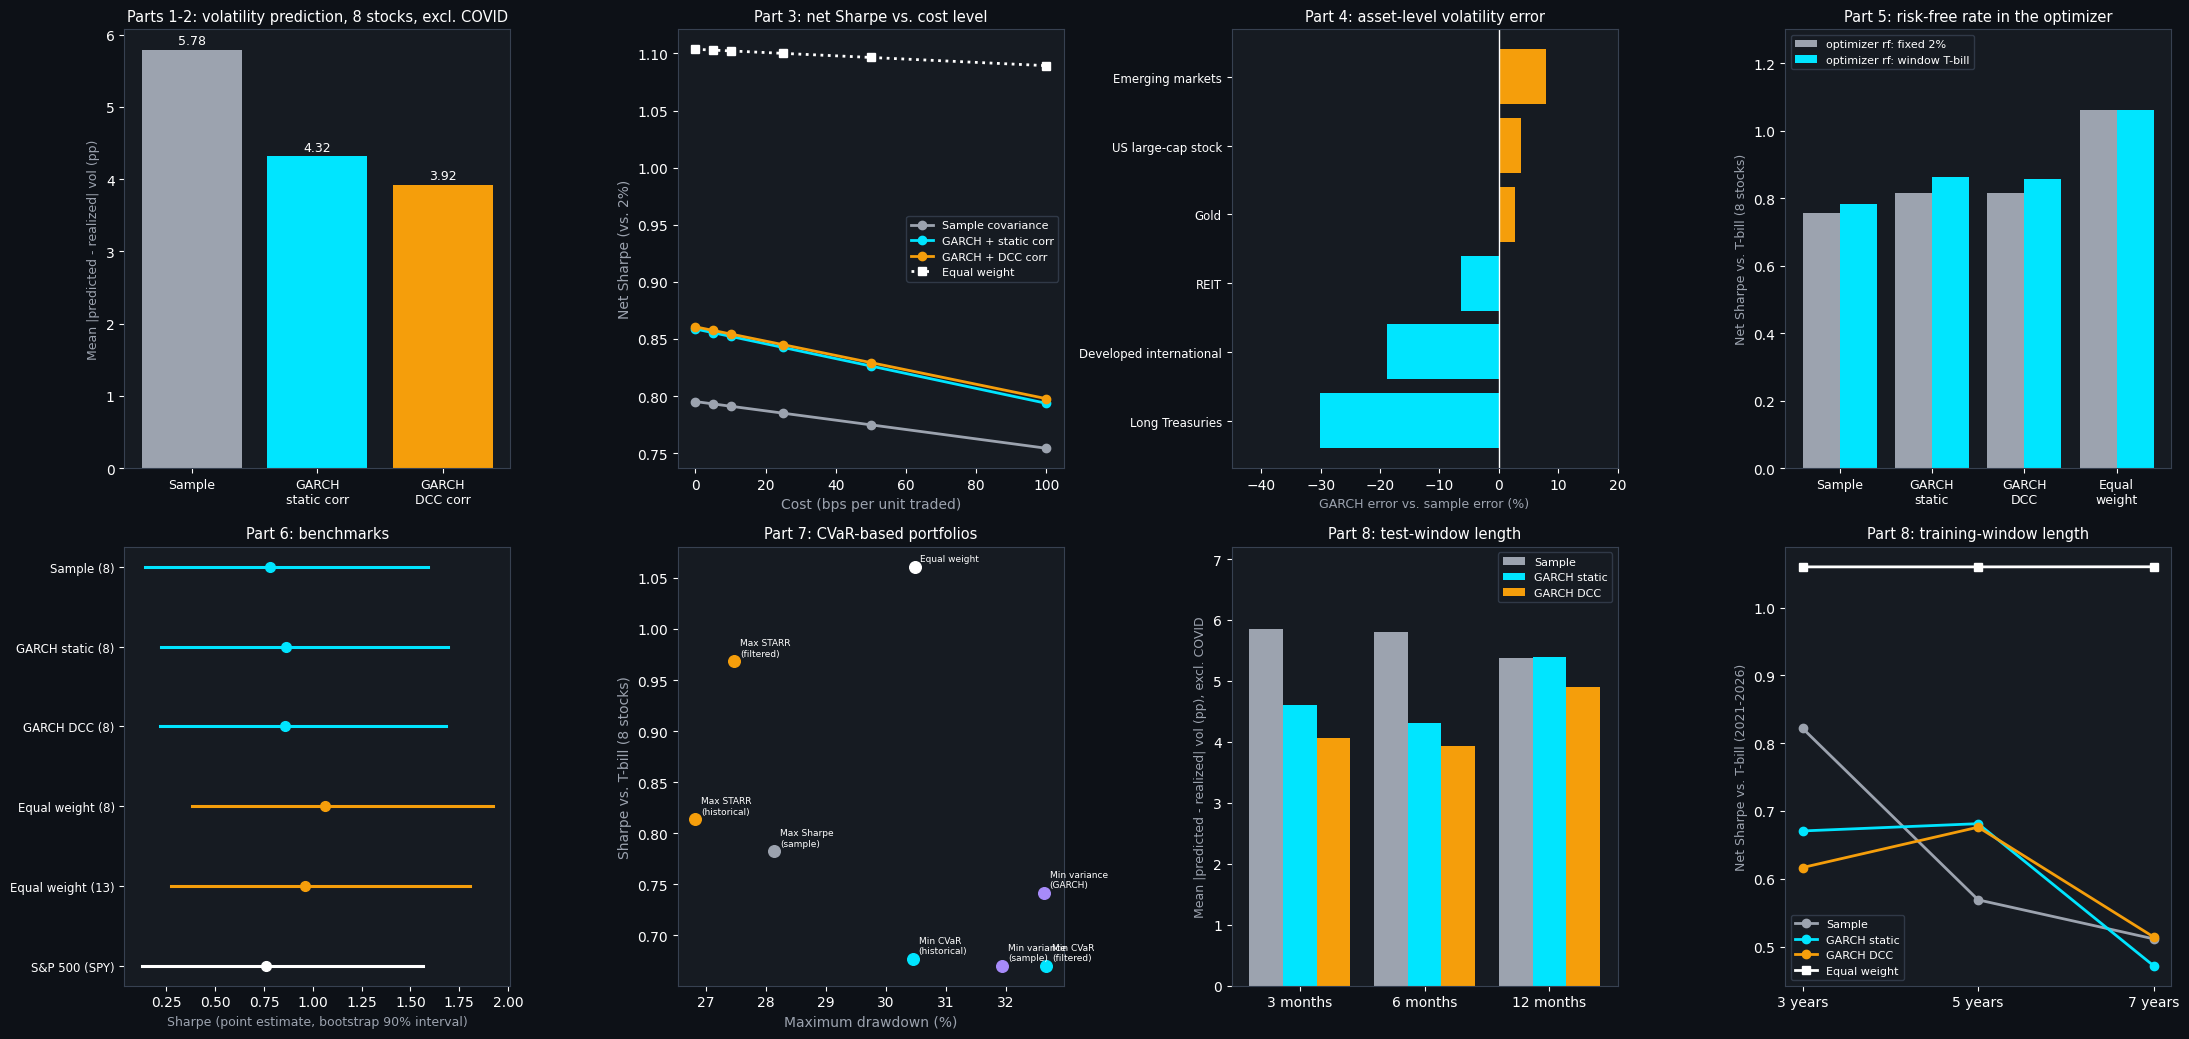

Saved chart_summary.png


In [4]:
fig, axes = plt.subplots(2, 4, figsize=(22, 10.5))
fig.patch.set_facecolor('#0d1117')
for ax in axes.ravel():
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#374151')
CY, OR, GY, WH, PU = '#00e5ff', '#f59e0b', '#9ca3af', '#ffffff', '#a78bfa'

# (1) Parts 1-2: vol error
ax = axes[0, 0]
vals = [ex['sample_error'].mean() * 100, ex['garch_static_error'].mean() * 100, ex['garch_dcc_error'].mean() * 100]
bars = ax.bar(range(3), vals, color=[GY, CY, OR])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width()/2, v + 0.08, f'{v:.2f}', ha='center', color='white', fontsize=9)
ax.set_xticks(range(3))
ax.set_xticklabels(['Sample', 'GARCH\nstatic corr', 'GARCH\nDCC corr'], color='white', fontsize=9)
ax.set_ylabel('Mean |predicted - realized| vol (pp)', color='#9ca3af', fontsize=9)
ax.set_title('Parts 1-2: volatility prediction, 8 stocks, excl. COVID', color='white', fontsize=10.5)

# (2) Part 3: net Sharpe vs cost
ax = axes[0, 1]
for name, col in (('Sample covariance', GY), ('GARCH + static corr', CY), ('GARCH + DCC corr', OR)):
    s = p3[(p3.covariance == name) & (p3.optimizer == 'cost-blind')].sort_values('cost_bps')
    ax.plot(s['cost_bps'], s['net_sharpe'], marker='o', color=col, lw=2, label=name)
s = p3[p3.covariance == 'Equal weight (1/N)'].sort_values('cost_bps')
ax.plot(s['cost_bps'], s['net_sharpe'], marker='s', color=WH, lw=2, ls=':', label='Equal weight')
ax.set_xlabel('Cost (bps per unit traded)', color='#9ca3af')
ax.set_ylabel('Net Sharpe (vs. 2%)', color='#9ca3af')
ax.set_title('Part 3: net Sharpe vs. cost level', color='white', fontsize=10.5)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=8, loc='center right')

# (3) Part 4: asset-level error by class
ax = axes[0, 2]
g = a.groupby('class').agg(s=('sample_err', 'mean'), g=('garch_err', 'mean'))
g['pct'] = 100 * (g['g'] / g['s'] - 1)
g = g.sort_values('pct')
cols = [CY if v < 0 else OR for v in g['pct']]
ax.barh(range(len(g)), g['pct'], color=cols)
ax.axvline(0, color='white', lw=1)
ax.set_yticks(range(len(g)))
ax.set_yticklabels(g.index, color='white', fontsize=8.5)
ax.set_xlabel('GARCH error vs. sample error (%)', color='#9ca3af', fontsize=9)
ax.set_title('Part 4: asset-level volatility error', color='white', fontsize=10.5)
ax.set_xlim(-45, 20)

# (4) Part 5
ax = axes[0, 3]
strategies = ['Sample', 'GARCH + static corr', 'GARCH + DCC corr', 'Equal weight (1/N)']
x = np.arange(len(strategies))
for off, mode, col in ((-0.2, 'fixed 2%', GY), (0.2, 'window T-bill', CY)):
    vals = [t.loc[s_, mode] for s_ in strategies]
    ax.bar(x + off, vals, 0.4, color=col, label=f'optimizer rf: {mode}')
ax.set_xticks(x)
ax.set_xticklabels(['Sample', 'GARCH\nstatic', 'GARCH\nDCC', 'Equal\nweight'], color='white', fontsize=9)
ax.set_ylabel('Net Sharpe vs. T-bill (8 stocks)', color='#9ca3af', fontsize=9)
ax.set_title('Part 5: risk-free rate in the optimizer', color='white', fontsize=10.5)
ax.set_ylim(0, 1.3)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=8, loc='upper left')

# (5) Part 6
ax = axes[1, 0]
order = ['Sample (8)', 'GARCH static (8)', 'GARCH DCC (8)', 'Equal weight (8)', 'Equal weight (13)', 'S&P 500 (SPY)']
y = np.arange(len(order))[::-1]
for yi, k in zip(y, order):
    col = WH if k.startswith('S&P') else (OR if k.startswith('Equal') else CY)
    ax.plot([p6.loc[k, 'boot_5%'], p6.loc[k, 'boot_95%']], [yi, yi], color=col, lw=2.2)
    ax.plot(p6.loc[k, 'sharpe_point'], yi, 'o', color=col, ms=7)
ax.set_yticks(y)
ax.set_yticklabels(order, color='white', fontsize=8.5)
ax.set_xlabel('Sharpe (point estimate, bootstrap 90% interval)', color='#9ca3af', fontsize=9)
ax.set_title('Part 6: benchmarks', color='white', fontsize=10.5)

# (6) Part 7
ax = axes[1, 1]
for _, r in q.iterrows():
    col = WH if r.name == 'Equal weight' else (OR if 'STARR' in r.name else (CY if 'CVaR' in r.name else (PU if 'variance' in r.name else GY)))
    ax.scatter(-r['max_dd_%'], r['sharpe'], color=col, s=70)
    ax.annotate(r.name.replace(' (', '\n('), (-r['max_dd_%'], r['sharpe']), xytext=(4, 4), textcoords='offset points', color='white', fontsize=6.5)
ax.set_xlabel('Maximum drawdown (%)', color='#9ca3af')
ax.set_ylabel('Sharpe vs. T-bill (8 stocks)', color='#9ca3af')
ax.set_title('Part 7: CVaR-based portfolios', color='white', fontsize=10.5)

# (7) Part 8 vol error by test window
ax = axes[1, 2]
cfgs = ['test 3m / train 5y', 'test 6m / train 5y', 'test 12m / train 5y']
x = np.arange(3)
for off, col_, lab, c_ in ((-0.27, 'Sample error %', 'Sample', GY), (0, 'GARCH static error %', 'GARCH static', CY), (0.27, 'GARCH DCC error %', 'GARCH DCC', OR)):
    ax.bar(x + off, [v8.loc[c, col_] for c in cfgs], 0.27, color=c_, label=lab)
ax.set_xticks(x)
ax.set_xticklabels(['3 months', '6 months', '12 months'], color='white')
ax.set_ylabel('Mean |predicted - realized| vol (pp), excl. COVID', color='#9ca3af', fontsize=9)
ax.set_title('Part 8: test-window length', color='white', fontsize=10.5)
ax.set_ylim(0, 7.2)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=8, loc='upper right')

# (8) Part 8 Sharpe by training length
ax = axes[1, 3]
g8 = p8p[p8p.group == 'training length (6m test)']
tcfg = ['test 6m / train 3y', 'test 6m / train 5y', 'test 6m / train 7y']
for lab, c_, mk in (('Sample', GY, 'o'), ('GARCH static', CY, 'o'), ('GARCH DCC', OR, 'o'), ('Equal weight', WH, 's')):
    ss = g8[g8.strategy == lab]
    ax.plot(range(3), [ss[ss.config == c]['sharpe'].iloc[0] for c in tcfg], marker=mk, color=c_, lw=2, label=lab)
ax.set_xticks(range(3))
ax.set_xticklabels(['3 years', '5 years', '7 years'], color='white')
ax.set_ylabel('Net Sharpe vs. T-bill (2021-2026)', color='#9ca3af', fontsize=9)
ax.set_title('Part 8: training-window length', color='white', fontsize=10.5)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=8)
plt.tight_layout()
plt.savefig('chart_summary.png', dpi=140, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Saved chart_summary.png')